In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 05 - Education, labour market and wages

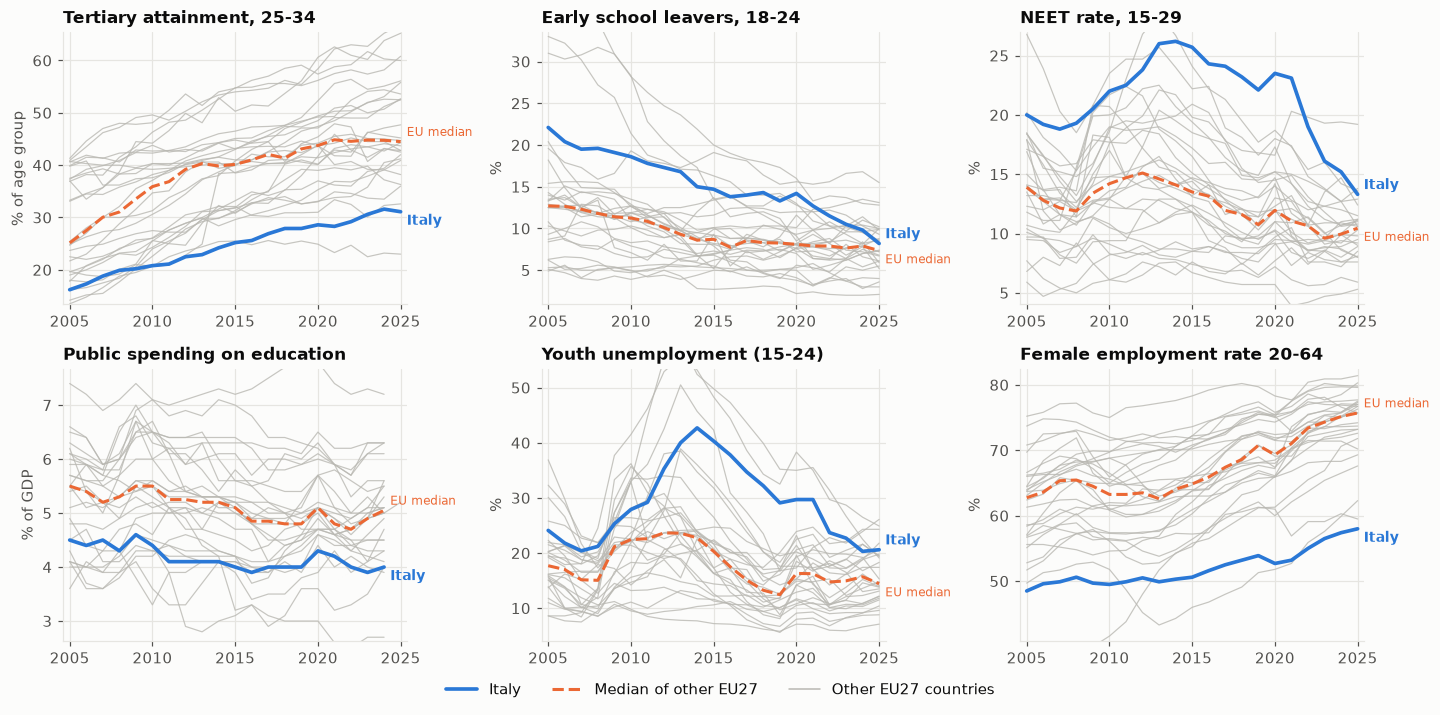

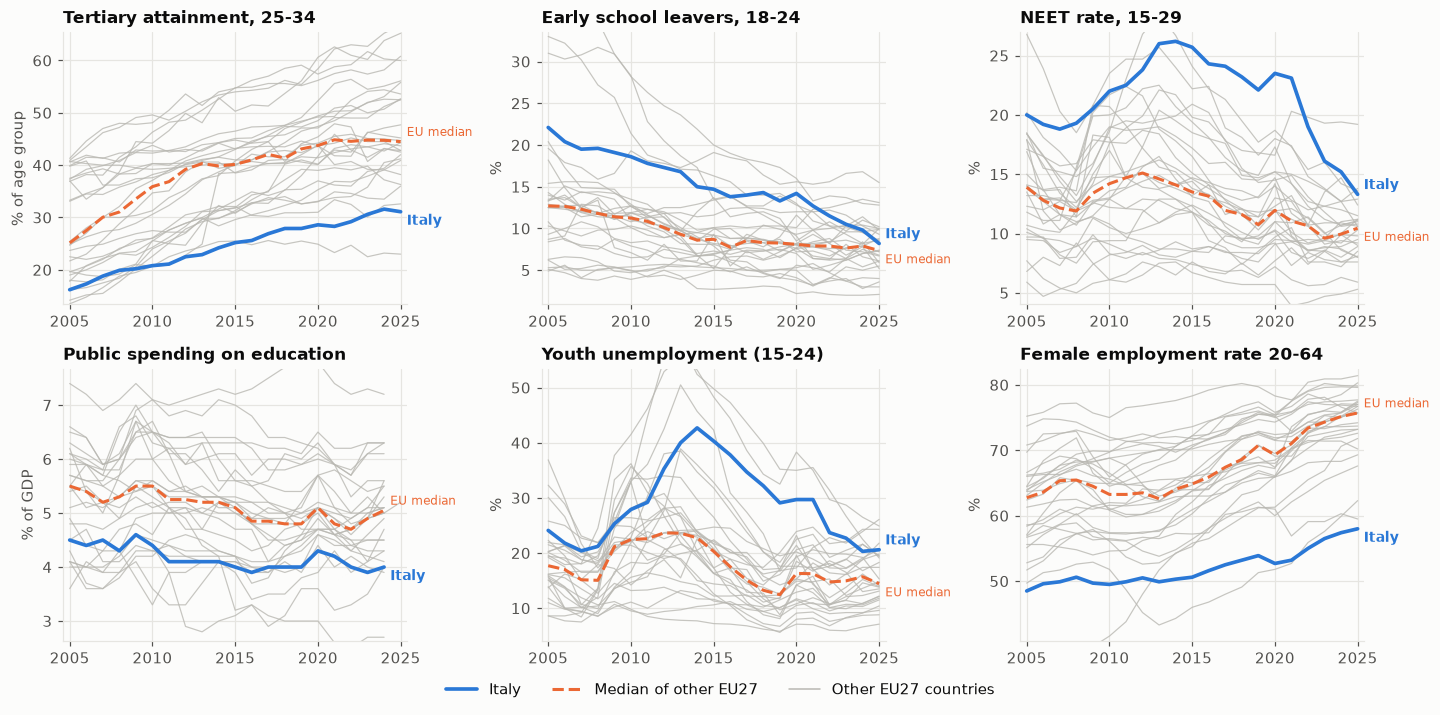

In [2]:
small_multiples(panel, [
    ("tertiary_attainment_25_34", "Tertiary attainment, 25-34", "% of age group"),
    ("early_leavers_18_24", "Early school leavers, 18-24", "%"),
    ("neet_rate_15_29", "NEET rate, 15-29", "%"),
    ("edu_spend_pct_gdp", "Public spending on education", "% of GDP"),
    ("youth_unemployment_rate", "Youth unemployment (15-24)", "%"),
    ("employment_rate_20_64_female", "Female employment rate 20-64", "%"),
], ncols=3, name="05_education_labour_overview")

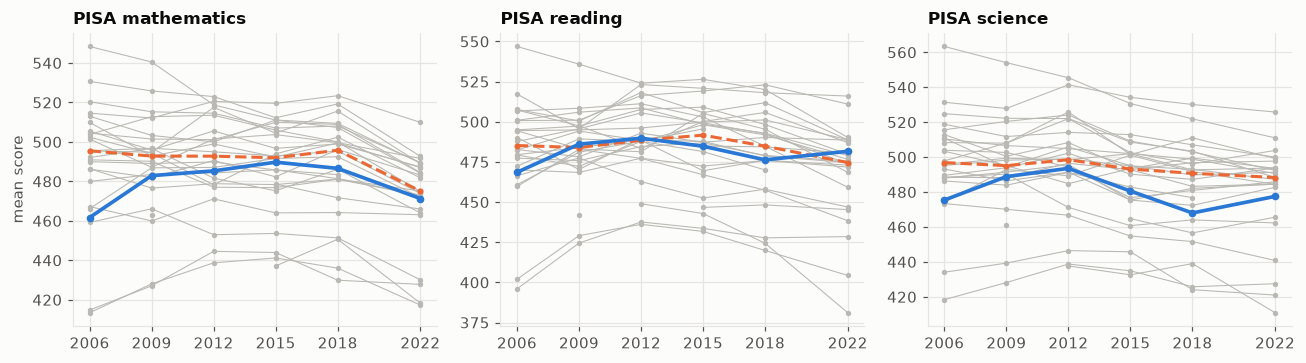

In [3]:
# PISA (World Bank EdStats up to 2018; 2022 from the OECD workbook via data/external/pisa_2022.csv)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
for ax, (ind, t) in zip(axes, [("wb_pisa_math", "PISA mathematics"), ("wb_pisa_reading", "PISA reading"), ("wb_pisa_science", "PISA science")]):
    w = wide(panel, ind).dropna(how="all")
    for c in EU27_ISO3:
        if c != ITALY and c in w: ax.plot(w.index, w[c], color=PEER_C, lw=0.7, marker="o", ms=2.5)
    ax.plot(w.index, eu_median_ex_italy(w), color=EU_C, lw=2, ls="--", marker="o", ms=3); ax.plot(w.index, w[ITALY], color=ITALY_C, lw=2.4, marker="o", ms=4); ax.set_title(t); ax.set_xticks(w.index)
axes[0].set_ylabel("mean score"); fig.tight_layout(); save(fig, "05_pisa")

{'ITA': 90.5, 'DEU': 110.0, 'FRA': 103.8, 'ESP': 105.4} EU median ex IT: 117.6


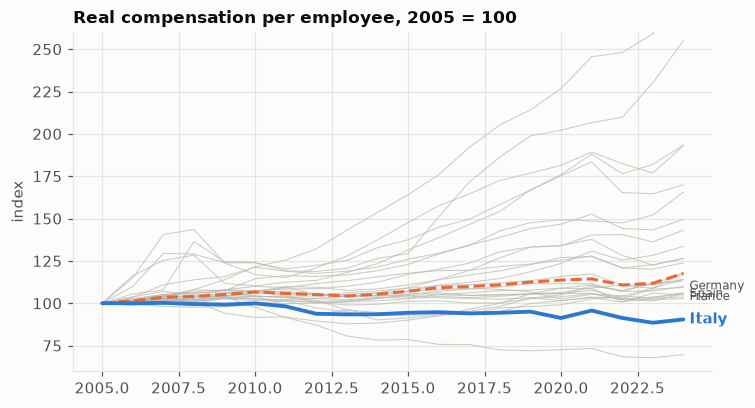

In [4]:
# Real compensation per employee (AMECO nominal compensation, deflated with cumulative HICP), 2005 = 100. Approximate: total economy, composition effects included.
comp = wide(panel, "ameco_comp_per_employee_ncu"); infl = wide(panel, "hicp_inflation")
price = (1 + infl / 100).cumprod(); price = price / price.loc[2005]
real = (comp / comp.loc[2005]) / price * 100
real = real.loc[2005:2024]
fig, ax = plt.subplots(figsize=(7.5, 4))
for c in EU27_ISO3:
    if c != ITALY and c in real: ax.plot(real.index, real[c], color=PEER_C, lw=0.7, alpha=0.7)
for c, lab in [("DEU", "Germany"), ("FRA", "France"), ("ESP", "Spain")]:
    ax.annotate(lab, (2024, real.loc[2024, c]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
ax.plot(real.index, eu_median_ex_italy(real), color=EU_C, lw=2, ls="--"); ax.plot(real.index, real[ITALY], color=ITALY_C, lw=2.5)
ax.annotate("Italy", (2024, real.loc[2024, ITALY]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
ax.set_ylim(60, 260); ax.set_title("Real compensation per employee, 2005 = 100"); ax.set_ylabel("index"); save(fig, "05_real_compensation")
print(real.loc[2024, [ITALY, "DEU", "FRA", "ESP"]].round(1).to_dict(), "EU median ex IT:", round(eu_median_ex_italy(real).loc[2024], 1))

Correlation across EU27: 0.62


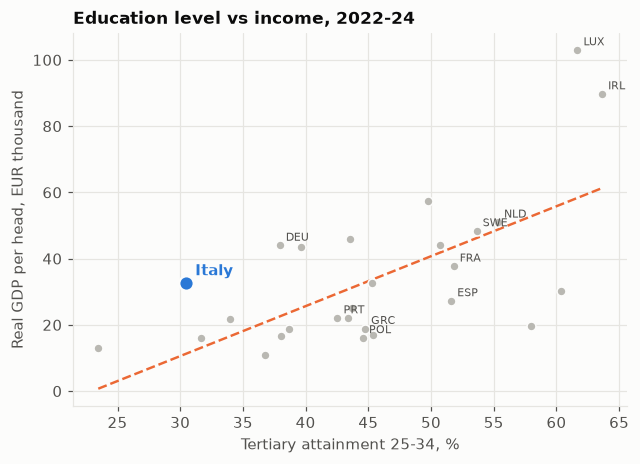

In [5]:
# Human capital vs income: tertiary attainment 25-34 and GDP per head (EU27, 2022-24 mean)
win = slice(2022, 2024)
x = wide(panel, "tertiary_attainment_25_34", EU27_ISO3).loc[win].mean(); y = wide(panel, "gdp_real_pc", EU27_ISO3).loc[win].mean() / 1000
fig, ax = plt.subplots(figsize=(6.5, 4.4)); scatter_italy(ax, x, y, "Tertiary attainment 25-34, %", "Real GDP per head, EUR thousand", "Education level vs income, 2022-24"); save(fig, "05_tertiary_gdp")
print("Correlation across EU27:", round(x.corr(y), 2))

In [6]:
# Figures quoted in the takeaways: Italy, median of the other members, rank (1 = highest) among the members with a value
def quoted(ind, years, countries=()):
    w = wide(panel, ind, EU27_ISO3)
    for y in years:
        r = w.loc[y].dropna()
        print(f"{ind} {y}: Italy {r[ITALY]:.2f} | median of the others {r.drop(ITALY).median():.2f} | rank {int(r.rank(ascending=False)[ITALY])}/{len(r)}" + "".join(f" | {c} {r[c]:.2f}" for c in countries))  # two decimals: a takeaway rounded to one is then checked without ties
quoted("tertiary_attainment_25_34", [2005, 2024]); quoted("edu_spend_pct_gdp", [2024]); quoted("early_leavers_18_24", [2005, 2024]); quoted("neet_rate_15_29", [2015, 2024]); quoted("youth_unemployment_rate", [2024])
quoted("wb_pisa_math", [2006, 2018, 2022], ["DEU"]); quoted("wb_pisa_reading", [2006, 2018, 2022], ["DEU", "FRA"]); quoted("wb_pisa_science", [2022])

tertiary_attainment_25_34 2005: Italy 16.20 | median of the others 25.15 | rank 24/27
tertiary_attainment_25_34 2024: Italy 31.60 | median of the others 44.75 | rank 26/27
edu_spend_pct_gdp 2024: Italy 4.00 | median of the others 5.05 | rank 24/27
early_leavers_18_24 2005: Italy 22.10 | median of the others 12.70 | rank 4/27
early_leavers_18_24 2024: Italy 9.80 | median of the others 7.90 | rank 8/27
neet_rate_15_29 2015: Italy 25.70 | median of the others 13.50 | rank 1/27
neet_rate_15_29 2024: Italy 15.20 | median of the others 9.95 | rank 2/27
youth_unemployment_rate 2024: Italy 20.30 | median of the others 15.70 | rank 7/27
wb_pisa_math 2006: Italy 461.69 | median of the others 495.48 | rank 22/25 | DEU 503.79
wb_pisa_math 2018: Italy 486.59 | median of the others 495.77 | rank 16/27 | DEU 500.04
wb_pisa_math 2022: Italy 471.30 | median of the others 475.10 | rank 19/26 | DEU 474.80
wb_pisa_reading 2006: Italy 468.52 | median of the others 485.21 | rank 20/25 | DEU 494.94 | FRA 487

## Takeaways
- **Tertiary attainment (25-34):** up from 16.2% to 31.6% but 26th of 27 (median 44.8%). Cross-country correlation with GDP per head: 0.62. Public education spending is 4.0% of GDP vs a 5.0% median (24th).
- **Early leavers fell sharply** (22.1% -> 9.8%, median 7.9%): this gap has nearly closed.
- **NEET (15-29)** was 25.7% in 2015 and is 15.2% in 2024, still the 2nd highest in the EU27 (median 10.0%). Youth unemployment is 20.3% vs 15.7%.
- **PISA:** Italian scores rose between 2006 and 2018 (maths 462 -> 487, reading 469 -> 476) and fell in 2022 to 471 in maths, 482 in reading (477 in science), a post-pandemic dip seen across countries. Germany's maths score fell from 504 (2006) to 475, so the gap with Italy went from 42 points to 4; in reading Italy (482) is now slightly above Germany (480) and France (474). Italy ranks 19th of 26 EU members in maths and 8th in reading in 2022. Spain's 2018 reading score is missing in the World Bank series. 2022 comes from the OECD workbook (docs/manual_data.md).
- **Real compensation per employee** (AMECO nominal compensation deflated with HICP, 2005 = 100) was 90.5 in 2024 against 110.0 Germany, 103.8 France, 105.4 Spain and a 118 median: Italy is the weak end, but note this is a total-economy average with composition effects, and the 2022-23 inflation spike drives much of the last years.